## 05. Outliers

Outliers are unusual observations, not automatically data errors. This notebook preserves the original IQR and multivariate analyses and the decision to retain observations. IQR bounds are exploratory estimates on training only; they are not registered as common rules or reused as thresholds for validation folds.

In [24]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from IPython.display import display

from house_prices_mlops.pipeline import load_stage
from house_prices_mlops.data_tracker import DataTracker

# Cargar datos con la preparación común
df_before = load_stage("common")
df_hp = df_before.copy()

# Cargar el registro de hallazgos y decisiones
tracker = DataTracker.load(df_hp)

# Consultar el perfil
profile = tracker.profile

display(profile)


,var,data_type,variable_type,unique_count,missing_count,missing_pct,zero_count,zero_pct,min,max,mean,median,std,skewness,kurtosis
0,Id,int64,identifier,1168,0,0.000000,0.0,0.000000,1.0,1460.0,730.904966,732.5,425.369088,0.000920,-1.215850
1,MSSubClass,string,nominal,15,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,MSZoning,object,nominal,5,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LotFrontage,float64,continuous,107,217,18.578767,0.0,0.000000,21.0,313.0,70.343849,70.0,24.897021,2.406787,19.454319
4,LotArea,int64,continuous,890,0,0.000000,0.0,0.000000,1300.0,215245.0,10689.642123,9600.0,10759.366198,11.958088,186.444082
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
88,HasBasement,int64,None,2,0,0.000000,28.0,2.397260,0.0,1.0,0.976027,1.0,0.153029,-6.232060,36.901760
89,HasPool,int64,None,2,0,0.000000,1162.0,99.486301,0.0,1.0,0.005137,0.0,0.071519,13.862369,190.491446
90,HasFireplace,int64,None,2,0,0.000000,547.0,46.832192,0.0,1.0,0.531678,1.0,0.499209,-0.127131,-1.987244
91,IsRemodeled,int64,None,2,0,0.000000,601.0,51.455479,0.0,1.0,0.485445,0.0,0.500002,0.058319,-2.000027


### Findings

In [25]:
outlier_keys = ["sale_price_iqr_outliers", "gr_liv_area_target_outliers"]
display(tracker.findings.loc[tracker.findings["key"].isin(outlier_keys)])


,key,var,stage,finding,status,resolution
7,gr_liv_area_target_outliers,GrLivArea,DU - Feature Analysis - Numeric vs Target,"Relación positiva fuerte con SalePrice, con ob...",pending,None
18,sale_price_iqr_outliers,SalePrice,DU - Target Analysis - Outliers,Las observaciones de entrenamiento en la cola ...,pending,None


### IQR Analysis

In [26]:
outlier_analysis = []

numeric_vars = tracker.profile.loc[
    tracker.profile['variable_type'].isin(['continuous', 'discrete']),
    'var'
]

for var in numeric_vars:

    q1 = df_hp[var].quantile(0.25)
    q3 = df_hp[var].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (df_hp[var] < lower) | (df_hp[var] > upper)

    outlier_analysis.append({
        'var': var,
        'lower_bound': lower,
        'upper_bound': upper,
        'outlier_count': mask.sum(),
        'outlier_pct': mask.mean() * 100
    })

outlier_analysis = pd.DataFrame(outlier_analysis)

display(
    outlier_analysis[
        outlier_analysis['outlier_count'] > 0
    ].sort_values('outlier_pct', ascending=False)
)

,var,lower_bound,upper_bound,outlier_count,outlier_pct
23,EnclosedPorch,0.000,0.000,160,13.698630
4,BsmtFinSF2,0.000,0.000,131,11.215753
25,ScreenPorch,0.000,0.000,97,8.304795
2,MasVnrArea,-249.000,415.000,77,6.592466
0,LotFrontage,27.500,111.500,68,5.821918
12,BsmtHalfBath,0.000,0.000,66,5.650685
22,OpenPorchSF,-111.000,185.000,60,5.136986
16,KitchenAbvGr,1.000,1.000,56,4.794521
1,LotArea,1418.125,17869.125,54,4.623288
28,SalePrice,2612.500,342312.500,48,4.109589


In [27]:
outlier_candidates = [
    'LotArea',
    'LotFrontage',
    'TotalBsmtSF',
    'BsmtUnfSF',
    'SalePrice',
    'BedroomAbvGr',
    'TotRmsAbvGrd',
    'GarageArea',
    'GrLivArea',
    '1stFlrSF',
    'GarageCars',
    'Fireplaces',
    '2ndFlrSF',
    'BsmtFullBath'
]
for var in outlier_candidates:
    display(
        df_hp[[var]]
        .sort_values(var)
        .iloc[np.r_[0:5, -5:0]]
    )

,LotArea
956,1300
1039,1477
489,1526
1038,1533
75,1596
1298,63887
706,115149
249,159000
335,164660
313,215245


,LotFrontage
1378,21.0
1007,21.0
1039,21.0
225,21.0
235,21.0
1429,NaN
1431,NaN
1441,NaN
1443,NaN
1446,NaN


,TotalBsmtSF
1000,0
39,0
553,0
90,0
102,0
1373,2633
440,3094
523,3138
496,3200
1298,6110


,BsmtUnfSF
17,0
1452,0
1445,0
1458,0
696,0
1267,2002
678,2046
278,2121
477,2153
224,2336


,SalePrice
495,34900
968,37900
533,39300
710,52000
1337,52500
769,538000
440,555000
803,582933
1169,625000
1182,745000


...

,1stFlrSF
533,334
705,372
1100,438
1378,483
232,483
1044,2524
1373,2633
523,3138
496,3228
1298,4692


,GarageCars
1453,0
39,0
48,0
1349,0
1325,0
456,3
747,4
1350,4
1190,4
420,4


,Fireplaces
1453,0
1452,0
1448,0
1446,0
1445,0
1426,2
1298,3
166,3
642,3
605,3


,2ndFlrSF
627,0
1114,0
1112,0
1093,0
1090,0
769,1589
1360,1611
1169,1796
304,1818
1182,2065


,BsmtFullBath
853,0
852,0
851,0
849,0
848,0
1298,2
420,2
921,2
313,2
738,3


### Individual Observations

Original row indices 1298, 523, 691, 1182 and 635 correspond to Id 1299, 524, 692, 1183 and 636 in raw/train.csv. Selection now uses Id. Any of these outside training are omitted from the analysis.

In [28]:
review_ids = [1299, 524, 692, 1183, 636]
cols = ["Id", "SalePrice", "GrLivArea", "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "OverallQual", "Neighborhood"]
display(df_hp.loc[df_hp["Id"].isin(review_ids), cols])

# Original focus observations, limited to training membership.
focus = df_hp.loc[df_hp["Id"].isin([524, 1299])].copy()
print("Focus Ids present in training:", focus["Id"].tolist())


,Id,SalePrice,GrLivArea,TotalBsmtSF,1stFlrSF,2ndFlrSF,OverallQual,Neighborhood
523,524,184750,4676,3138,3138,1538,10,Edwards
635,636,200000,3395,1440,1440,1440,6,SWISU
1182,1183,745000,4476,2396,2411,2065,10,NoRidge
1298,1299,160000,5642,6110,4692,950,10,Edwards


Focus Ids present in training: [524, 1299]


### Multivariate Review

In [29]:
if not focus.empty:
    tracker.add_finding(
        key="gr_liv_area_multivariate_outliers",
        var="GrLivArea", stage="DP - Outliers",
        finding=(
            f"Las viviendas de entrenamiento con Id {sorted(focus['Id'].tolist())} son observaciones atípicas multivariadas: "
            "presentan GrLivArea muy elevada y OverallQual=10, pero SalePrice inusualmente bajo respecto a viviendas comparables."
        ),
    )
    display(tracker.findings.loc[tracker.findings["key"].eq("gr_liv_area_multivariate_outliers")])


,key,var,stage,finding,status,resolution
23,gr_liv_area_multivariate_outliers,GrLivArea,DP - Outliers,"Las viviendas de entrenamiento con Id [524, 12...",pending,None


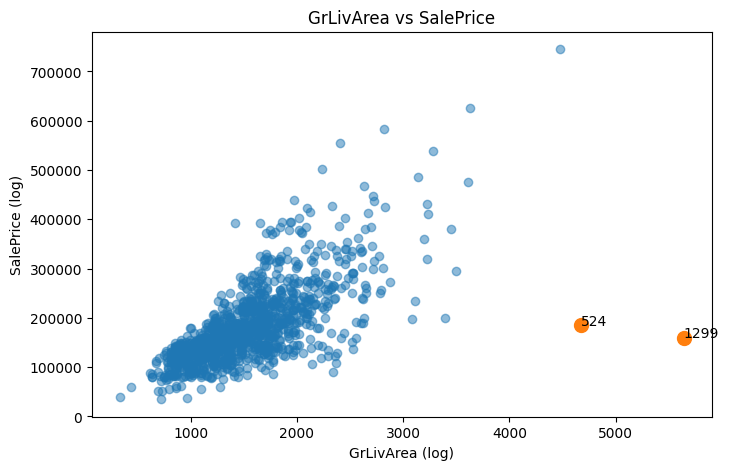

In [30]:
plt.figure(figsize=(8, 5))
plt.scatter(df_hp["GrLivArea"], df_hp["SalePrice"], alpha=0.5)
plt.scatter(focus["GrLivArea"], focus["SalePrice"], s=100)
for _, row in focus.iterrows():
    plt.annotate(str(int(row["Id"])), (row["GrLivArea"], row["SalePrice"]))
plt.xlabel("GrLivArea (log)")
plt.ylabel("SalePrice (log)")
plt.title("GrLivArea vs SalePrice")
plt.show()


In [31]:
with pd.option_context("display.max_columns", None):
    display(focus)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,HouseAge,RemodAge,GarageAge,TotalSF,TotalBathrooms,TotalPorchSF,HasGarage,HasBasement,HasPool,HasFireplace,IsRemodeled,QualGrLivArea
523,524,60,RL,130.0,40094,Pave,None,IR1,Bnk,AllPub,Inside,Gtl,Edwards,PosN,PosN,1Fam,2Story,10,5,2007,2008,Hip,CompShg,CemntBd,CmentBd,Stone,762.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,2260,Unf,0,878,3138,GasA,Ex,Y,SBrkr,3138,1538,0,4676,1,0,3,1,3,1,Ex,11,Typ,1,Gd,BuiltIn,2007.0,Fin,3,884,TA,TA,Y,208,406,0,0,0,0,None,None,None,0,10,2007,New,Partial,184750,0,0,0.0,7814,4.5,614,1,1,0,1,1,46760
1298,1299,60,RL,313.0,63887,Pave,None,IR3,Bnk,AllPub,Corner,Gtl,Edwards,Feedr,Norm,1Fam,2Story,10,5,2008,2008,Hip,ClyTile,Stucco,Stucco,Stone,796.0,Ex,TA,PConc,Ex,TA,Gd,GLQ,5644,Unf,0,466,6110,GasA,Ex,Y,SBrkr,4692,950,0,5642,2,0,2,1,3,1,Ex,12,Typ,3,Gd,Attchd,2008.0,Fin,2,1418,TA,TA,Y,214,292,0,0,0,480,Gd,None,None,0,1,2008,New,Partial,160000,0,0,0.0,11752,4.5,506,1,1,1,1,0,56420


In [32]:
comparison = df_hp[
    (df_hp['Neighborhood'] == 'Edwards') &
    (df_hp['OverallQual'] >= 8)
][[
    'GrLivArea',
    'TotalSF',
    'OverallQual',
    'SaleType',
    'SaleCondition',
    'SalePrice'
]].sort_values('GrLivArea')

display(comparison)

,GrLivArea,TotalSF,OverallQual,SaleType,SaleCondition,SalePrice
724,1698,3396,9,WD,Normal,320000
523,4676,7814,10,New,Partial,184750
1298,5642,11752,10,New,Partial,160000


### Retain Observations

The original retained the highlighted cases because no data error was confirmed. Unusual values alone do not justify deleting rows. The IQR tables identify candidates for review; they do not prove that every flagged observation is erroneous. All rows and original Ids are retained.

In [33]:
if not focus.empty:
    tracker.resolve_finding(
        key="gr_liv_area_multivariate_outliers",
        resolution="Se conservaron las observaciones revisadas: son extremas, pero no se confirmó un error de datos.",
    )
    tracker.log(
        var="GrLivArea", stage="DP - Outliers", action="retain_outliers",
        method="multivariate_analysis",
        before=f"Training Ids {sorted(focus['Id'].tolist())} identified as multivariate outliers",
        after="Retained: extreme but plausible observations",
    )
    tracker.resolve_finding(
        key="gr_liv_area_target_outliers",
        resolution="Se revisaron las observaciones extremas de GrLivArea presentes en entrenamiento y se conservaron al no confirmarse errores de datos.",
    )

tracker.log(
    var="multiple", stage="DP - Outliers", action="retain_outliers",
    method="IQR + domain + multivariate_analysis",
    before="Outliers detected across multiple numeric variables",
    after="Retained: no confirmed data errors; extremes considered plausible",
)
tracker.resolve_finding(
    key="sale_price_iqr_outliers",
    resolution="Las observaciones de la cola superior se revisaron y conservaron siguiendo la decisión original; no se aplicó eliminación automática por IQR.",
)


### Validation

In [34]:
assert len(df_hp) == len(df_before)
pd.testing.assert_series_equal(df_hp["Id"], df_before["Id"])
pd.testing.assert_frame_equal(df_before, load_stage("common"))
pd.testing.assert_frame_equal(df_hp, df_before)


### Save Decisions

In [35]:
tracker.save()
